# Example 3: Si and GaAs p–n electrostatics and C–V

The same nominal abrupt junction is applied to Si and GaAs so that the effects of intrinsic concentration and permittivity remain visible.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import elementary_charge as q, Boltzmann as k_B, epsilon_0

ROOT = Path.cwd()
while not (ROOT / "notebooks" / "la2_models.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the LA2 workspace")
    ROOT = ROOT.parent
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
# Direct depletion calculation.
from la2_models import SILICON,GAAS,intrinsic_concentration_m3

T=300.0; NA=1e23; ND=1e22
VR=np.linspace(0,20,301)
direct=[]
for material in (SILICON,GAAS):
    ni=float(intrinsic_concentration_m3(material,T)); VT=k_B*T/q
    Vbi=VT*np.log(NA*ND/ni**2); eps=material.relative_permittivity*epsilon_0
    W=np.sqrt(2*eps*(Vbi+VR)/q*(1/NA+1/ND)); C=eps/W
    direct.append((material,ni,Vbi,eps,W,C))
    print(material.name,f"ni={ni/1e6:.3e} cm^-3, Vbi={Vbi:.4f} V, W0={W[0]*1e6:.3f} µm")

Si ni=6.117e+09 cm^-3, Vbi=0.7993 V, W0=0.337 µm
GaAs ni=2.043e+06 cm^-3, Vbi=1.2131 V, W0=0.436 µm


In [2]:
from la2_models import abrupt_junction

profiles=[]
for material,ni,Vbi,eps,W,C in direct:
    equilibrium=abrupt_junction(material,T,NA,ND)
    reverse=abrupt_junction(material,T,NA,ND,-10.0)
    assert abs(equilibrium["built_in_V"]-Vbi)<1e-12
    assert abs(NA*equilibrium["p_width_m"]-ND*equilibrium["n_width_m"])/(ND*equilibrium["n_width_m"])<1e-12
    profiles.append((material,equilibrium,reverse))

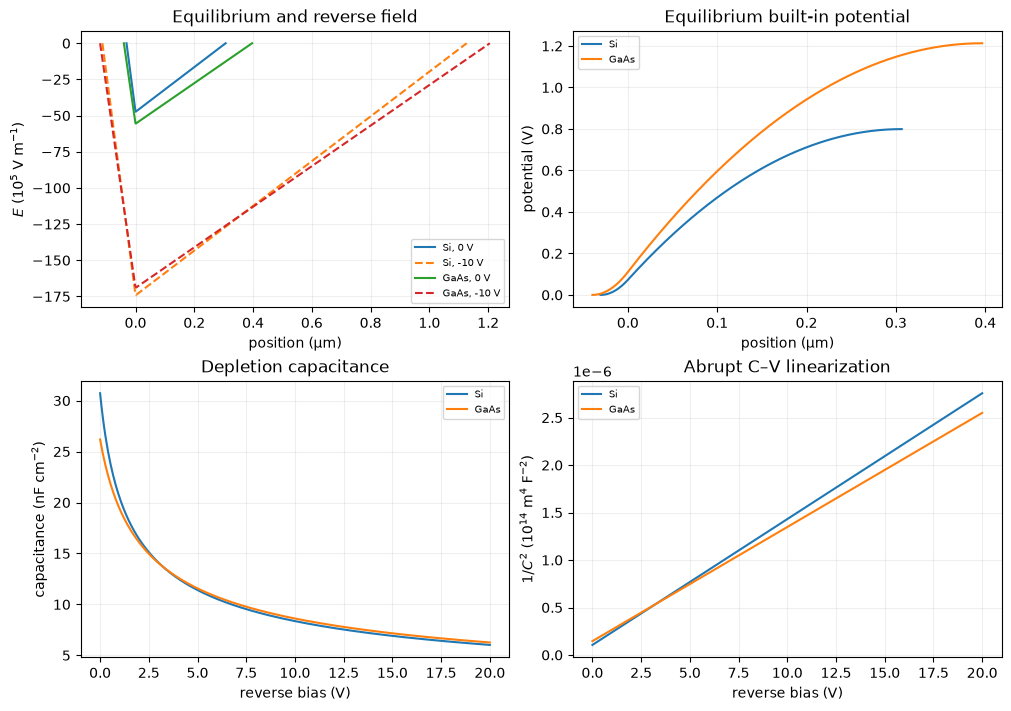

In [3]:
fig,axes=plt.subplots(2,2,figsize=(10,7),layout="constrained")
for material,equilibrium,reverse in profiles:
    axes[0,0].plot(equilibrium["position_m"]*1e6,equilibrium["field_V_m"]/1e5,label=f"{material.name}, 0 V")
    axes[0,0].plot(reverse["position_m"]*1e6,reverse["field_V_m"]/1e5,"--",label=f"{material.name}, -10 V")
    axes[0,1].plot(equilibrium["position_m"]*1e6,equilibrium["potential_V"],label=material.name)
for material,ni,Vbi,eps,W,C in direct:
    axes[1,0].plot(VR,C*1e5,label=material.name)
    axes[1,1].plot(VR,1/C**2/1e14,label=material.name)
axes[0,0].set(xlabel="position (µm)",ylabel="$E$ ($10^5$ V m$^{-1}$)",title="Equilibrium and reverse field")
axes[0,1].set(xlabel="position (µm)",ylabel="potential (V)",title="Equilibrium built-in potential")
axes[1,0].set(xlabel="reverse bias (V)",ylabel="capacitance (nF cm$^{-2}$)",title="Depletion capacitance")
axes[1,1].set(xlabel="reverse bias (V)",ylabel="$1/C^2$ ($10^{14}$ m$^4$ F$^{-2}$)",title="Abrupt C–V linearization")
for ax in axes.flat: ax.grid(alpha=.2); ax.legend(fontsize=7)
fig.savefig(FIGURES/'example-si-gaas-pn-electrostatics.pdf',metadata={'CreationDate':None,'ModDate':None})
plt.show()

In [4]:
# C–V slope recovers the reduced doping NA*ND/(NA+ND), not simply nominal ND.
expected=NA*ND/(NA+ND)
for material,ni,Vbi,eps,W,C in direct:
    slope=np.gradient(1/C**2,VR,edge_order=2)
    extracted=2/(q*eps*slope)
    error=np.max(abs(extracted-expected))/expected
    print(material.name,f"C–V extraction relative error={error:.3e}")
    assert error<1e-10
print("wrote figures/example-si-gaas-pn-electrostatics.pdf")

Si C–V extraction relative error=1.105e-13
GaAs C–V extraction relative error=2.272e-13
wrote figures/example-si-gaas-pn-electrostatics.pdf
